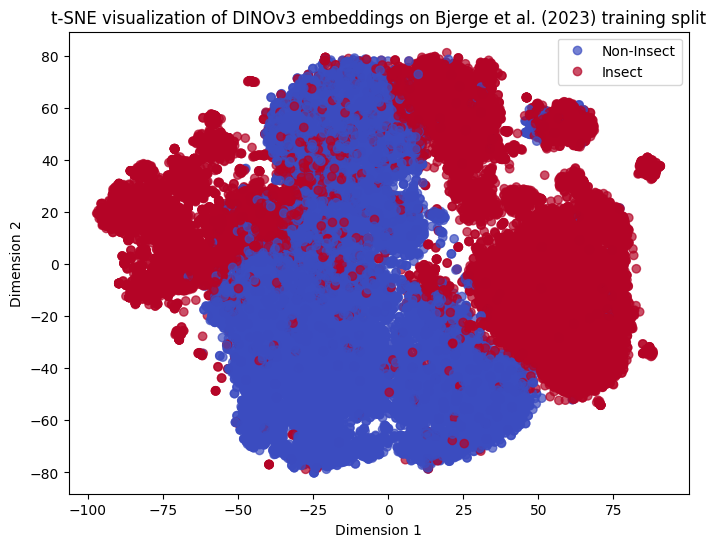

In [ ]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import torch

def visualize_embeddings(embeddings, labels, title):
    tsne = TSNE(n_components=2, random_state=42)
    embeddings = tsne.fit_transform(embeddings)

    plt.figure(figsize=(8, 6))
    scatter = plt.scatter(embeddings[:, 0], embeddings[:, 1], c=labels, cmap='coolwarm', alpha=0.7)

    unique_labels = ["Non-Insect", "Insect"] 

    plt.legend(handles=scatter.legend_elements()[0], labels=unique_labels)
    plt.title(title)
    plt.xlabel("Dimension 1")
    plt.ylabel("Dimension 2")
    plt.show()

MODEL_NAME = "dinov3" # "dinov3", "bioclip2_5", "eupe_vitb16"
embeddings_data = torch.load(f"extracted_embeddings/ecostack_train_embeddings_{MODEL_NAME}.pt")
embeddings = embeddings_data["features"]
labels = embeddings_data["labels"]
    
visualize_embeddings(embeddings, labels, title=f"t-SNE visualization of DINOv3 embeddings on Bjerge et al. (2023) training split")

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import classification_report, roc_auc_score
import sys
import os
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..")))
from utils.models import BaseMLP
import random
import numpy as np

random_seed = 42

def set_seed(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed) # if using multi-GPU
    
    # Force deterministic operations
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(random_seed)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

MODEL_NAME = "bioclip2_5" # "dinov3", "bioclip2_5", "eupe_vitb16"

def load_and_concatenate_splits(file_paths, samples_per_class=None, random_seed=42):
    X_list, y_list = [], []

    for path in file_paths:
        data = torch.load(path, weights_only=True)

        if samples_per_class is not None:
            generator = torch.Generator().manual_seed(random_seed)
            pos_indices = (data["labels"] == 1).nonzero(as_tuple=True)[0]
            neg_indices = (data["labels"] == 0).nonzero(as_tuple=True)[0]

            num_pos_samples = samples_per_class // len(file_paths) // 2
            num_neg_samples = samples_per_class // len(file_paths) // 2 * 2

            selected_pos_indices = torch.randperm(len(pos_indices), generator=generator)[:num_pos_samples]
            selected_neg_indices = torch.randperm(len(neg_indices), generator=generator)[:num_neg_samples]

            selected_indices = torch.cat([pos_indices[selected_pos_indices], neg_indices[selected_neg_indices]])
            
            data["features"] = data["features"][selected_indices]
            data["labels"] = data["labels"][selected_indices]

        X_list.append(data["features"])
        y_list.append(data["labels"])

        print(f"Loaded {data['features'].shape[0]} samples from {path}")
    
    X_combined = torch.cat(X_list, dim=0).to(DEVICE)
    y_combined = torch.cat(y_list, dim=0).float().to(DEVICE)
    return X_combined, y_combined

sample_per_class = None

X_train, y_train = load_and_concatenate_splits([
    f"extracted_embeddings/pitfall_train_embeddings_{MODEL_NAME}.pt",
    f"extracted_embeddings/ecostack_train_embeddings_{MODEL_NAME}.pt"
], samples_per_class=sample_per_class, random_seed=random_seed)

X_val, y_val = load_and_concatenate_splits([
    f"extracted_embeddings/pitfall_val_embeddings_{MODEL_NAME}.pt",
    f"extracted_embeddings/ecostack_val_embeddings_{MODEL_NAME}.pt"
])

X_test_idd , y_test_idd = load_and_concatenate_splits([
    f"extracted_embeddings/pitfall_test_embeddings_{MODEL_NAME}.pt",
    f"extracted_embeddings/ecostack_test_embeddings_{MODEL_NAME}.pt"
])

X_test_ood , y_test_ood = load_and_concatenate_splits([
    # f"extracted_embeddings/greenland_test_embeddings_{MODEL_NAME}.pt",
    f"extracted_embeddings/rangex_test_embeddings_{MODEL_NAME}.pt",
    f"extracted_embeddings/stefan_test_embeddings_{MODEL_NAME}.pt"
])

print(f"Train size: {X_train.shape[0]} | Val size: {X_val.shape[0]} | Test(IDD) size: {X_test_idd.shape[0]} | Test(OOD) size: {X_test_ood.shape[0]}")

train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=64, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=64, shuffle=False)
test_idd_loader = DataLoader(TensorDataset(X_test_idd, y_test_idd), batch_size=64, shuffle=False)
test_ood_loader = DataLoader(TensorDataset(X_test_ood, y_test_ood), batch_size=64, shuffle=False)


input_dimension = X_train.shape[1]
model = BaseMLP(input_dim=input_dimension, hidden_dim=512, dropout_rate=0.5).to(DEVICE)

num_positives = y_train.sum().item()
num_negatives = len(y_train) - num_positives
pos_weight = torch.tensor([num_negatives / (num_positives + 1e-5)]).to(DEVICE)

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)

epochs = 50

for epoch in range(epochs):
    model.train()
    total_loss = 0
    
    for batch_x, batch_y in train_loader:
        optimizer.zero_grad()
        logits = model(batch_x)
        loss = criterion(logits, batch_y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
        
    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch+1}/{epochs} | Loss: {total_loss/len(train_loader):.4f}")

def evaluate_model(loader, name="Validation"):
    model.eval()
    all_preds, all_probs, all_targets = [], [], []
    
    with torch.no_grad():
        for batch_x, batch_y in loader:
            logits = model(batch_x)
            probs = torch.sigmoid(logits)
            preds = (probs >= 0.5).float()
            
            all_probs.extend(probs.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(batch_y.cpu().numpy())
            
    print(f"\n{name} Results")
    print(classification_report(all_targets, all_preds, target_names=["background", "insect"]))
    print(f"ROC-AUC: {roc_auc_score(all_targets, all_probs):.4f}")

evaluate_model(val_loader, "Validation")
evaluate_model(test_idd_loader, "Test (IDD)")
evaluate_model(test_ood_loader, "Test (OOD)")

save_data = {
    "input_dim": input_dimension,
    "dropout_rate": 0.5,
    "model_state_dict": model.state_dict()
}
save_dir = os.path.join(os.environ.get("MODEL_CACHE_DIR", os.path.join("..", "models-cache")), "binary_classificator")
os.makedirs(save_dir, exist_ok=True)
save_path = os.path.join(save_dir, f"insect_classifier_ecostack_mlp_{MODEL_NAME}{f'_spc{sample_per_class}_seed{random_seed}' if sample_per_class else ''}.pth")

torch.save(save_data, save_path)

print(f"\nModel saved to {save_path}")

Loaded 11308 samples from extracted_embeddings/pitfall_train_embeddings_bioclip2_5.pt
Loaded 48050 samples from extracted_embeddings/ecostack_train_embeddings_bioclip2_5.pt
Loaded 2424 samples from extracted_embeddings/pitfall_val_embeddings_bioclip2_5.pt
Loaded 6514 samples from extracted_embeddings/ecostack_val_embeddings_bioclip2_5.pt
Loaded 2402 samples from extracted_embeddings/pitfall_test_embeddings_bioclip2_5.pt
Loaded 17798 samples from extracted_embeddings/ecostack_test_embeddings_bioclip2_5.pt
Loaded 3159 samples from extracted_embeddings/rangex_test_embeddings_bioclip2_5.pt
Loaded 47404 samples from extracted_embeddings/stefan_test_embeddings_bioclip2_5.pt
Train size: 59358 | Val size: 8938 | Test(IDD) size: 20200 | Test(OOD) size: 50563
Epoch 10/50 | Loss: 0.0291
Epoch 20/50 | Loss: 0.0157
Epoch 30/50 | Loss: 0.0106
Epoch 40/50 | Loss: 0.0082
Epoch 50/50 | Loss: 0.0066

Validation Results
              precision    recall  f1-score   support

  background       0.98      0

In [5]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import classification_report, roc_auc_score
import sys
import os
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..")))
from utils.models import BaseMLP

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

MODEL_NAME = "bioclip2_5" # "dinov3", "bioclip2_5", "eupe_vitb16"

def load_and_concatenate_splits(file_paths, samples_per_class=None, random_seed=42):
    X_list, y_list = [], []

    for path in file_paths:
        data = torch.load(path, weights_only=True)

        if samples_per_class is not None:
            generator = torch.Generator().manual_seed(random_seed)
            pos_indices = (data["labels"] == 1).nonzero(as_tuple=True)[0]
            neg_indices = (data["labels"] == 0).nonzero(as_tuple=True)[0]

            num_pos_samples = samples_per_class // len(file_paths) // 2
            num_neg_samples = samples_per_class // len(file_paths) // 2 * 2

            selected_pos_indices = torch.randperm(len(pos_indices), generator=generator)[:num_pos_samples]
            selected_neg_indices = torch.randperm(len(neg_indices), generator=generator)[:num_neg_samples]

            selected_indices = torch.cat([pos_indices[selected_pos_indices], neg_indices[selected_neg_indices]])
            
            data["features"] = data["features"][selected_indices]
            data["labels"] = data["labels"][selected_indices]

        X_list.append(data["features"])
        y_list.append(data["labels"])

        print(f"Loaded {data['features'].shape[0]} samples from {path}")
    
    X_combined = torch.cat(X_list, dim=0).to(DEVICE)
    y_combined = torch.cat(y_list, dim=0).float().to(DEVICE)
    return X_combined, y_combined

def evaluate_model(loader, name="Validation"):
    model.eval()
    all_preds, all_probs, all_targets = [], [], []
    
    with torch.no_grad():
        for batch_x, batch_y in loader:
            logits = model(batch_x)
            probs = torch.sigmoid(logits)
            preds = (probs >= 0.5).float()
            
            all_probs.extend(probs.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(batch_y.cpu().numpy())
            
    print(f"\n{name} Results")
    print(classification_report(all_targets, all_preds, target_names=["background", "insect"]))
    print(f"ROC-AUC: {roc_auc_score(all_targets, all_probs):.4f}")

sample_per_class = None
random_seed = 42

X_train, y_train = load_and_concatenate_splits([
    f"extracted_embeddings/pitfall_train_embeddings_{MODEL_NAME}.pt",
    f"extracted_embeddings/ecostack_train_embeddings_{MODEL_NAME}.pt"
], samples_per_class=sample_per_class, random_seed=random_seed)

X_val, y_val = load_and_concatenate_splits([
    f"extracted_embeddings/pitfall_val_embeddings_{MODEL_NAME}.pt",
    f"extracted_embeddings/ecostack_val_embeddings_{MODEL_NAME}.pt"
])

X_test_idd , y_test_idd = load_and_concatenate_splits([
    f"extracted_embeddings/pitfall_test_embeddings_{MODEL_NAME}.pt",
    f"extracted_embeddings/ecostack_test_embeddings_{MODEL_NAME}.pt"
])

X_test_ood , y_test_ood = load_and_concatenate_splits([
    # f"extracted_embeddings/greenland_test_embeddings_{MODEL_NAME}.pt",
    f"extracted_embeddings/rangex_test_embeddings_{MODEL_NAME}.pt",
    f"extracted_embeddings/stefan_test_embeddings_{MODEL_NAME}.pt"
])

print(f"Train size: {X_train.shape[0]} | Val size: {X_val.shape[0]} | Test(IDD) size: {X_test_idd.shape[0]} | Test(OOD) size: {X_test_ood.shape[0]}")

train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=64, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=64, shuffle=False)
test_idd_loader = DataLoader(TensorDataset(X_test_idd, y_test_idd), batch_size=64, shuffle=False)
test_ood_loader = DataLoader(TensorDataset(X_test_ood, y_test_ood), batch_size=64, shuffle=False)

save_dir = os.path.join(os.environ.get("MODEL_CACHE_DIR", os.path.join("..", "models-cache")), "binary_classificator")
save_path = os.path.join(save_dir, f"insect_classifier_ecostack_mlp_{MODEL_NAME}.pth")

model_ckpt = torch.load(save_path)
model = BaseMLP(input_dim=model_ckpt["input_dim"], dropout_rate=model_ckpt["dropout_rate"]).to(DEVICE)
model.load_state_dict(model_ckpt["model_state_dict"])

evaluate_model(test_idd_loader, "Test (IDD)")
evaluate_model(test_ood_loader, "Test (OOD)")


Loaded 11308 samples from extracted_embeddings/pitfall_train_embeddings_bioclip2_5.pt
Loaded 48050 samples from extracted_embeddings/ecostack_train_embeddings_bioclip2_5.pt
Loaded 2424 samples from extracted_embeddings/pitfall_val_embeddings_bioclip2_5.pt
Loaded 6514 samples from extracted_embeddings/ecostack_val_embeddings_bioclip2_5.pt
Loaded 2402 samples from extracted_embeddings/pitfall_test_embeddings_bioclip2_5.pt
Loaded 17798 samples from extracted_embeddings/ecostack_test_embeddings_bioclip2_5.pt
Loaded 3159 samples from extracted_embeddings/rangex_test_embeddings_bioclip2_5.pt
Loaded 47404 samples from extracted_embeddings/stefan_test_embeddings_bioclip2_5.pt
Train size: 59358 | Val size: 8938 | Test(IDD) size: 20200 | Test(OOD) size: 50563

Test (IDD) Results
              precision    recall  f1-score   support

  background       0.97      0.99      0.98     10100
      insect       0.99      0.97      0.98     10100

    accuracy                           0.98     20200
  